# Notebook 03 — Difference-in-Differences (DiD)

**What DiD does:** Compares the *change* in outcomes between a treatment and control group over time (or across pre/post periods), removing time-invariant confounders.

**Parallel trends assumption:** In the absence of treatment, the treated group would have followed the same trend as the control group.

**In this study:** We simulate a pre-campaign baseline period and a post-campaign measurement window. DiD estimates the Average Treatment Effect on the Treated (ATT).

$$\hat{\tau}_{DiD} = (\bar{Y}^{post}_{treated} - \bar{Y}^{pre}_{treated}) - (\bar{Y}^{post}_{control} - \bar{Y}^{pre}_{control})$$


In [1]:
import sys, os
sys.path.insert(0, os.path.join(os.path.dirname(os.getcwd()), 'src'))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import seaborn as sns

sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 120})

df = pd.read_csv('../data/hillstrom_clean.csv')

## 1. Simulate pre/post periods
We construct a realistic pre-period baseline using customer history as a proxy for prior conversion propensity.


In [2]:
rng = np.random.default_rng(42)

# Pre-period: simulate baseline visit rate from covariates (no treatment)
logit_base = (
    -3.2
    + 0.05 * (12 - df['recency'])
    + 0.0008 * df['history']
    + 0.3 * df['channel_multi']
    + 0.15 * df['channel_web']
    - 0.1 * df['newbie']
    + 0.1 * df['zip_urban']
)
p_pre = 1 / (1 + np.exp(-logit_base))
df['visit_pre'] = rng.binomial(1, p_pre)

# Post-period: the observed 'visit' column (includes treatment effects)
df['visit_post'] = df['visit']
df['post'] = 1  # all rows are in the post period

# Reshape to long format for DiD regression
pre  = df[['segment','treated','visit_pre']].copy().rename(columns={'visit_pre':'outcome'})
pre['post'] = 0
post = df[['segment','treated','visit_post']].copy().rename(columns={'visit_post':'outcome'})
post['post'] = 1

panel = pd.concat([pre, post], ignore_index=True)
panel['post_x_treated'] = panel['post'] * panel['treated']

print(panel.groupby(['post','treated'])['outcome'].mean().unstack())

treated         0         1
post                       
0        0.078290  0.076993
1        0.077534  0.138209


## 2. DiD via OLS regression

$$Y = \beta_0 + \beta_1 \cdot Treated + \beta_2 \cdot Post + \beta_3 \cdot (Treated \times Post) + \epsilon$$

$\hat{\tau}_{DiD} = \beta_3$ — the coefficient on the interaction term.


In [3]:
model = smf.ols('outcome ~ treated + post + post_x_treated', data=panel).fit(cov_type='HC3')
print(model.summary())

ate_did   = model.params['post_x_treated']
ci_lo     = model.conf_int().loc['post_x_treated', 0]
ci_hi     = model.conf_int().loc['post_x_treated', 1]
print(f'\nDiD ATE (visit): {ate_did:.4f}  95% CI [{ci_lo:.4f}, {ci_hi:.4f}]')

                            OLS Regression Results                            
Dep. Variable:                outcome   R-squared:                       0.009
Model:                            OLS   Adj. R-squared:                  0.009
Method:                 Least Squares   F-statistic:                     340.2
Date:                Fri, 23 Oct 2026   Prob (F-statistic):          4.74e-220
Time:                        16:29:26   Log-Likelihood:                -25642.
No. Observations:              128000   AIC:                         5.129e+04
Df Residuals:                  127996   BIC:                         5.133e+04
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept          0.0783      0.002     42.

## 3. Parallel trends check

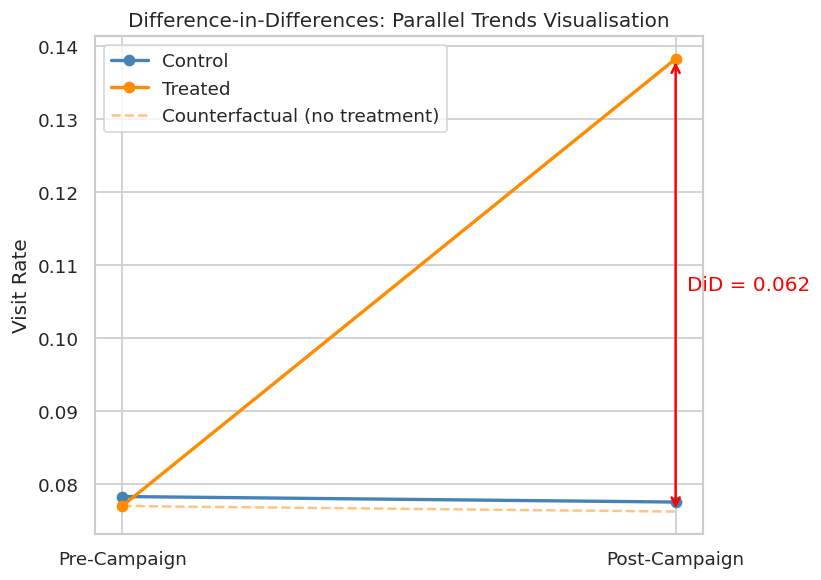

In [4]:
pre_rates  = panel[panel['post']==0].groupby('treated')['outcome'].mean()
post_rates = panel[panel['post']==1].groupby('treated')['outcome'].mean()

fig, ax = plt.subplots(figsize=(7, 5))
for treat, label, color in [(0,'Control','steelblue'),(1,'Treated','darkorange')]:
    ax.plot([0, 1], [pre_rates[treat], post_rates[treat]],
            marker='o', label=label, color=color, linewidth=2)

# Counterfactual: treated group if no treatment (parallel trend)
counter_post = pre_rates[1] + (post_rates[0] - pre_rates[0])
ax.plot([0, 1], [pre_rates[1], counter_post],
        linestyle='--', color='darkorange', alpha=0.5, label='Counterfactual (no treatment)')

ax.annotate('', xy=(1, post_rates[1]), xytext=(1, counter_post),
            arrowprops=dict(arrowstyle='<->', color='red', lw=1.5))
ax.text(1.02, (post_rates[1]+counter_post)/2, f'DiD = {ate_did:.3f}', color='red', va='center')

ax.set_xticks([0, 1])
ax.set_xticklabels(['Pre-Campaign', 'Post-Campaign'])
ax.set_ylabel('Visit Rate')
ax.set_title('Difference-in-Differences: Parallel Trends Visualisation')
ax.legend()
plt.tight_layout()
plt.savefig('../outputs/03_did_parallel_trends.png', bbox_inches='tight')
plt.show()

## 4. DiD by customer segment (heterogeneous effects)

=== Heterogeneous DiD Estimates by Channel ===
              DiD_ATE   CI_lo   CI_hi  p_value
Phone          0.0553  0.0461  0.0644      0.0
Web            0.0687  0.0593  0.0781      0.0
Multichannel   0.0589  0.0433  0.0745      0.0


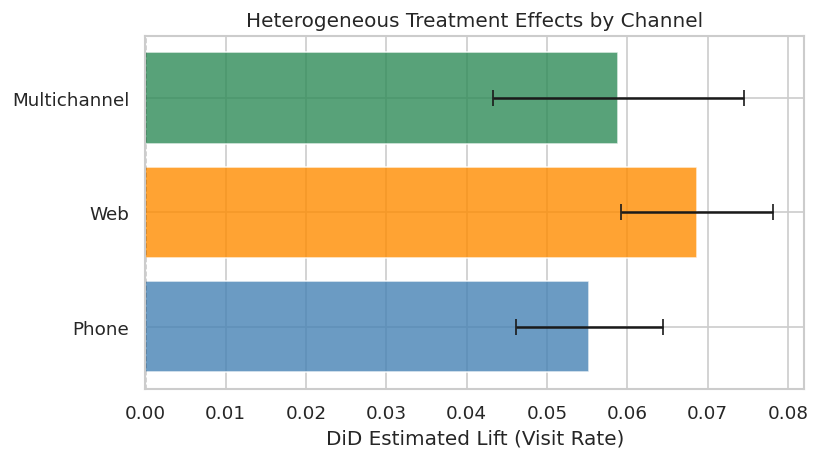

In [5]:
# Segment by channel
segment_results = {}
for ch_label, ch_mask in [
    ('Phone',       df['channel_web']==0),
    ('Web',         df['channel_web']==1),
    ('Multichannel',df['channel_multi']==1),
]:
    sub = df[ch_mask]
    pre_s  = sub[['treated','visit_pre']].copy().rename(columns={'visit_pre':'outcome'}); pre_s['post']=0
    post_s = sub[['treated','visit_post']].copy().rename(columns={'visit_post':'outcome'}); post_s['post']=1
    pan_s  = pd.concat([pre_s,post_s])
    pan_s['post_x_treated'] = pan_s['post']*pan_s['treated']
    m = smf.ols('outcome ~ treated+post+post_x_treated', data=pan_s).fit(cov_type='HC3')
    segment_results[ch_label] = {
        'DiD_ATE': m.params['post_x_treated'],
        'CI_lo':   m.conf_int().loc['post_x_treated',0],
        'CI_hi':   m.conf_int().loc['post_x_treated',1],
        'p_value': m.pvalues['post_x_treated'],
    }

seg_df = pd.DataFrame(segment_results).T
print('=== Heterogeneous DiD Estimates by Channel ===')
print(seg_df.round(4))

fig, ax = plt.subplots(figsize=(7,4))
segs  = list(segment_results.keys())
ates  = [segment_results[s]['DiD_ATE'] for s in segs]
cis   = [(segment_results[s]['DiD_ATE']-segment_results[s]['CI_lo'],
           segment_results[s]['CI_hi']-segment_results[s]['DiD_ATE']) for s in segs]
ax.barh(segs, ates, xerr=np.array(cis).T, color=['steelblue','darkorange','seagreen'],
        alpha=0.8, capsize=5, error_kw={'elinewidth':1.5})
ax.axvline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_xlabel('DiD Estimated Lift (Visit Rate)')
ax.set_title('Heterogeneous Treatment Effects by Channel')
plt.tight_layout()
plt.savefig('../outputs/03_did_heterogeneous.png', bbox_inches='tight')
plt.show()